# Spatial Accessibility with Pysal Access

**Authors:** Alexander Michels

In this notebook, we use the Pysall `access` package to calculate spatial accessibility to hospital beds using multiple methods.

In [1]:
import access
import contextily as cx
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm
import sys

In [2]:
pop_id = "FIPS"
figsize=(16, 14)

In [3]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop[pop_id] = pop[pop_id].astype(str)
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.7623 41.79274, -87.75251 41.7928..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.6902 42.01682, -87.6902 42.01744..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.0155, -87.70866 42.0191..."


In [4]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.8914)


In [5]:
hospitals = gpd.sjoin(pop[["FIPS", "geometry"]], hos[["BEDS", "geometry"]], how="inner", predicate="intersects")
hospitals = hospitals.groupby("FIPS").agg({"BEDS": 'sum', "geometry": 'last'})
print(len(hospitals), sum(hospitals["BEDS"]))
hospitals.head()

59 18259


,BEDS,geometry
FIPS,,
17031031000,189,"POLYGON ((-87.67441 41.9761, -87.66961 41.9761..."
17031031300,115,"POLYGON ((-87.65499 41.9764, -87.65428 41.9764..."
17031031400,184,"POLYGON ((-87.65012 41.96916, -87.64964 41.969..."
17031032100,134,"POLYGON ((-87.65634 41.96176, -87.65475 41.961..."
17031040300,279,"POLYGON ((-87.70582 41.98309, -87.70401 41.983..."


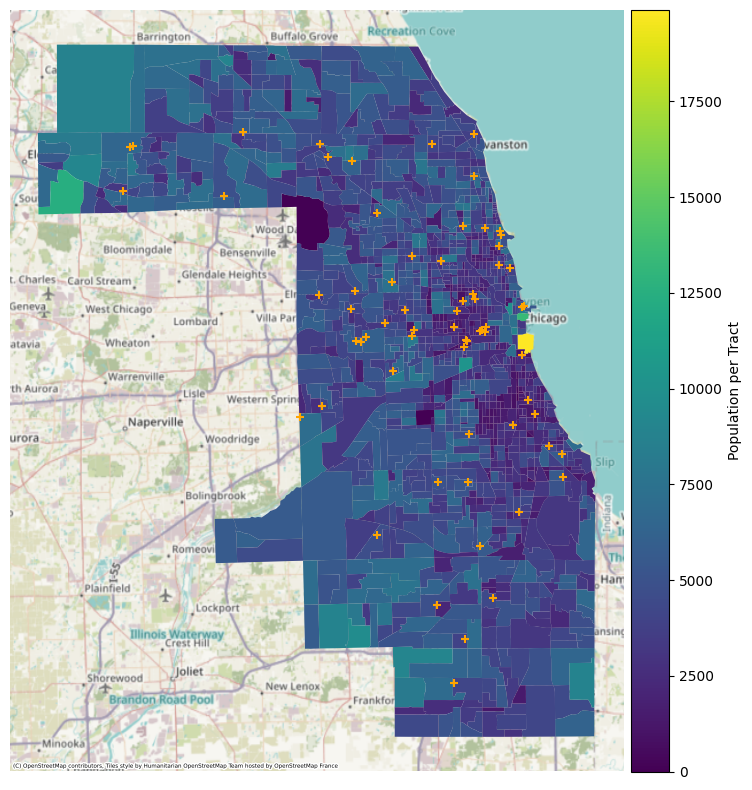

In [6]:
ax = pop.plot(column="E_TOTPOP", legend=True, figsize=(8,8), legend_kwds={'label': "Population per Tract", 'pad': 0.01})
ax = hos.plot(ax=ax, marker="+", color="orange", legend=True)
cx.add_basemap(ax=ax, crs=pop.crs.to_string(), attribution_size='4')
ax.axis('off')
plt.tight_layout()
plt.savefig("../figs/PopAndHospitals.png", dpi=200)
plt.show()

In [7]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/travel_times/17031-output-TRACT-CAR.csv'

In [ ]:
# calculate the gravity-based access
A = access.Access(
    demand_df=pop,
    demand_index=pop_id,
    demand_value="E_TOTPOP",
    supply_df=hospitals,
    supply_index=True,
    supply_value="BEDS",
    cost_df=car,
    cost_origin="origin",
    cost_dest="destination",
    cost_name="minutes",
    neighbor_cost_df=car,
    neighbor_cost_origin="origin",
    neighbor_cost_dest="destination",
    neighbor_cost_name="minutes"
)

In [ ]:
gravity = access.weights.gravity(scale=60, alpha=-2, min_dist=1)
e2sfca_weights_30 = access.weights.step_fn({10 : 1, 20 : 0.68, 30 : 0.22})
e2sfca_weights_60 = access.weights.step_fn({20 : 1, 40 : 0.68, 60 : 0.22})
gaussian10 = access.weights.gaussian(10)
gaussian20 = access.weights.gaussian(20)

In [ ]:
A.weighted_catchment(name="gravity", weight_fn=gravity)

In [ ]:
A.two_stage_fca(name="2sfca_30", max_cost=30)
A.two_stage_fca(name="2sfca_60", max_cost=60)

In [ ]:
A.enhanced_two_stage_fca(name="e2sfca_30", weight_fn=e2sfca_weights_30, max_cost=30)
A.enhanced_two_stage_fca(name="e2sfca_60", weight_fn=e2sfca_weights_60, max_cost=60)

In [ ]:
A.enhanced_two_stage_fca(name="g2sfca10", weight_fn=gaussian10)
A.enhanced_two_stage_fca(name="g2sfca20", weight_fn=gaussian20)

In [ ]:
A.three_stage_fca(name="3sfca")

In [ ]:
A.raam(name="raam30", tau=30)
A.raam(name="raam60", tau=60)

In [ ]:
print(len(A.access_df))
A.access_df.head()

In [ ]:
access_result = A.access_df.merge(pop[["FIPS", "geometry"]], left_index=True, right_on="FIPS").set_index("FIPS")
access_result = gpd.GeoDataFrame(access_result)
access_result = access_result.drop(columns=["E_TOTPOP"])
print(len(access_result))
print(type(access_result))
access_result.head()

In [ ]:
supply_field = "BEDS"
result_cols = [
    "gravity",
    "2sfca_30", "2sfca_60", "e2sfca_30", 
    "e2sfca_60", "g2sfca10", "g2sfca20",
    "3sfca", "raam30", "raam60"
]
result_cols = [x + f"_{supply_field}" for x in result_cols]
result_title_mapper = [
    "Gravity",
    "2SFCA 30 mins",
    "2SFCA 60 mins",
    "E2SFCA 30 mins",
    "E2SFCA 60 mins",
    "Gaussian 2SFCA 10",
    "Gaussian 2SFCA 20",
    "3SFCA",
    "RAAM 30",
    "RAAM 60"
]

In [ ]:
result = A.access_df.reset_index()
result[pop_id] = result[pop_id].astype(str)
# replace zeroes with nan to help distinguish between low and no access
for result_col in result_cols:
    result[result_col] = result[result_col].replace(0, np.nan)
    if "fca" in result_col:
        result[result_col] = result[result_col] * 1000
result.head()

In [ ]:
geom_result = gpd.GeoDataFrame(pop[[pop_id, "geometry"]].merge(result, on=pop_id))
geom_result = geom_result.set_crs(pop.crs)
for i, result_col in enumerate(result_cols):
    fig, ax = plt.subplots(figsize=figsize)
    ax = geom_result.plot(ax=ax, column=result_col, figsize=figsize, legend=True, antialiased=False,
                                missing_kwds= dict(color = "grey",), legend_kwds={'pad' : 0.01})
    ax.set_title(result_title_mapper[i])
    ax.margins(0.01)
    fig.subplots_adjust(hspace=0.0, wspace=0.0)
    ax.set_axis_off()
    cx.add_basemap(ax, attribution_size=6, crs=geom_result.crs.to_string())
geom_result.head()

In [ ]:
corr = access_result.corr(method='kendall', numeric_only=True)
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

In [ ]:
access_result.to_file("../data/accessibility/CookHospitals.gpkg", driver="GPKG")